# Лабораторная работа 2

## Тема: Геометрическая прогрессия

### 1. Задача 1

1. Импорт библиотек и задание многочлена

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Коэффициенты многочлена P(x) = -2.8x^3 - 8.9x^2 - 1.9x + 2.3
# numpy.poly1d принимает коэффициенты от старшей степени к младшей
coeffs = [-2.8, -8.9, -1.9, 2.3]
P = np.poly1d(coeffs)
print("P(x) =", P)

P(x) =       3       2
-2.8 x - 8.9 x - 1.9 x + 2.3


 2. Корни через numpy.root


In [6]:
roots_np = np.roots(coeffs)
print("Корни (numpy.root):")
for i, r in enumerate(roots_np, 1):
    print(f"  корень {i}: {r:.6f}")

Корни (numpy.root):
  корень 1: -2.837387
  корень 2: -0.735042
  корень 3: 0.393857


3. Графическая локализация корней

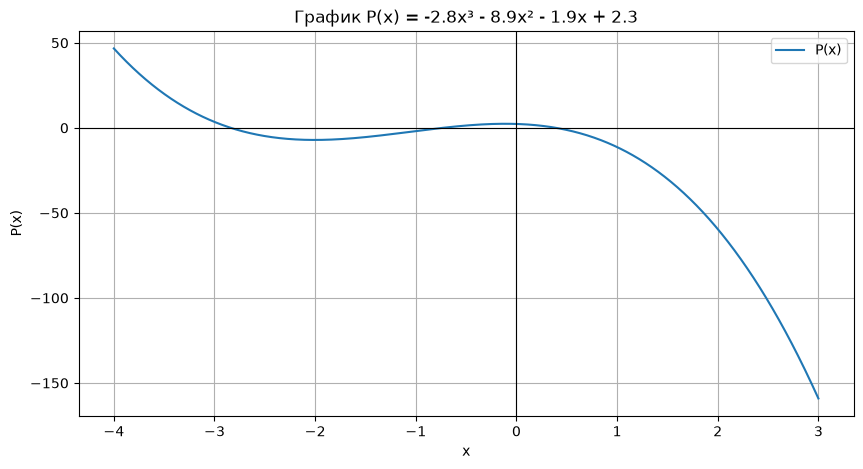

In [7]:
x = np.linspace(-4, 3, 1000)
y = P(x)

plt.figure(figsize=(10, 5))
plt.plot(x, y, label='P(x)')
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.grid(True)
plt.title('График P(x) = -2.8x³ - 8.9x² - 1.9x + 2.3')
plt.xlabel('x')
plt.ylabel('P(x)')
plt.legend()
plt.show()

Из графика видно три вещественных корня. Локализуем их интервалы:

In [8]:
# Найдём интервалы смены знака
x_test = np.linspace(-4, 3, 1000)
y_test = P(x_test)
intervals = []
for i in range(len(x_test) - 1):
    if y_test[i] * y_test[i+1] < 0:
        intervals.append((x_test[i], x_test[i+1]))
print("Интервалы локализации корней:")
for a, b in intervals:
    print(f"  [{a:.4f}, {b:.4f}]")

Интервалы локализации корней:
  [-2.8438, -2.8368]
  [-0.7417, -0.7347]
  [0.3934, 0.4004]


4. Метод Ньютона


In [10]:
def newton_method(f, df, x0, eps=1e-6, max_iter=1000):
    x = x0
    for n in range(1, max_iter + 1):
        fx = f(x)
        dfx = df(x)
        if abs(dfx) < 1e-15:
            raise ValueError("Производная близка к нулю")
        x_new = x - fx / dfx
        if abs(x_new - x) < eps:
            return x_new, n
        x = x_new
    return x, max_iter

# Производная P'(x) = -8.4x^2 - 17.8x - 1.9
dP = P.deriv()
print("P'(x) =", dP)

P'(x) =       2
-8.4 x - 17.8 x - 1.9


5. Метод бисекции (индивидуальный вариант)

In [12]:
def bisection_method(f, a, b, eps=1e-6, max_iter=10000):
    fa = f(a)
    fb = f(b)
    if fa * fb > 0:
        raise ValueError("На концах интервала функция одного знака")
    for n in range(1, max_iter + 1):
        c = (a + b) / 2
        fc = f(c)
        if abs(b - a) < eps or abs(fc) < eps:
            return c, n
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return (a + b) / 2, max_iter

6. Нахождение всех корней двумя методами

In [13]:
eps = 1e-6
results = []

for i, (a, b) in enumerate(intervals, 1):
    # Начальное приближение для Ньютона — середина интервала
    x0 = (a + b) / 2

    root_newton, n_newton = newton_method(P, dP, x0, eps)
    root_bisect, n_bisect = bisection_method(P, a, b, eps)

    # Соответствующий корень из numpy
    root_np = min(roots_np, key=lambda r: abs(r.real - root_newton))

    results.append({
        'i': i,
        'newton_root': root_newton, 'newton_n': n_newton,
        'bisect_root': root_bisect, 'bisect_n': n_bisect,
        'numpy_root': root_np.real
    })

# Таблица результатов
print(f"{'корень':<8}{'Ньютон':<22}{'Бисекция':<22}{'numpy.root':<15}")
print("-" * 70)
for r in results:
    print(f"{r['i']:<8}"
          f"{r['newton_root']:<12.6f} (n={r['newton_n']:<4}) "
          f"{r['bisect_root']:<12.6f} (n={r['bisect_n']:<4}) "
          f"{r['numpy_root']:<15.6f}")

корень  Ньютон                Бисекция              numpy.root     
----------------------------------------------------------------------
1       -2.837387    (n=3   ) -2.837386    (n=14  ) -2.837387      
2       -0.735042    (n=3   ) -0.735042    (n=14  ) -0.735042      
3       0.393857     (n=3   ) 0.393857     (n=14  ) 0.393857       


***Вывод: все три метода дают совпадающие корни с точностью 10⁻⁶. Метод Ньютона за счёт квадратичной сходимости требует в ~4–5 раз меньше итераций, чем метод бисекции (3 против 14). Однако бисекция гарантированно сходится при любом локализованном корне, тогда как Ньютон зависит от выбора начального приближения.***

### 2. Задача 2

1. Импорт и определение функции


In [33]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

def f(x):
    return np.sqrt(3*x - 1) - np.cos(x)

def df(x):
    return 3/(2*np.sqrt(3*x - 1)) + np.sin(x)

2. Локализация корня

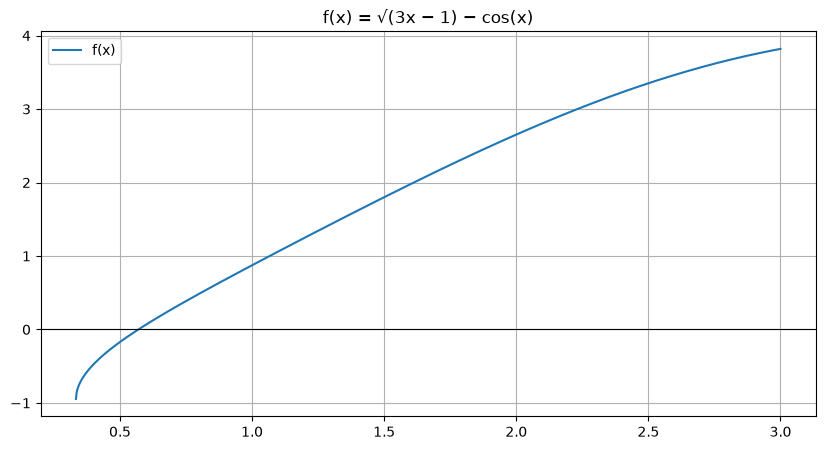

Корень локализован на [0.5682, 0.5709]


In [34]:
x = np.linspace(1/3, 3, 1000)
y = f(x)

plt.figure(figsize=(10, 5))
plt.plot(x, y, label='f(x)')
plt.axhline(0, color='black', linewidth=0.8)
plt.grid(True)
plt.title('f(x) = √(3x − 1) − cos(x)')
plt.legend()
plt.show()

# Интервал смены знака
for i in range(len(x) - 1):
    if y[i] * y[i+1] < 0:
        print(f"Корень локализован на [{x[i]:.4f}, {x[i+1]:.4f}]")

3. Решение через fsolve

In [35]:
root_fsolve = fsolve(f, 0.7)[0]
print(f"fsolve: x = {root_fsolve:.10f}, f(x) = {f(root_fsolve):.2e}")

fsolve: x = 0.5696922741, f(x) = 1.44e-15


4. Приведение к виду x = φ(x) и проверка сходимости

In [36]:
# Приведение: x = (cos^2(x) + 1)/3
def phi(x):
    return (np.cos(x)**2 + 1) / 3

def dphi(x):
    return -np.sin(2*x) / 3

# Проверка условия сходимости в окрестности корня
a, b = 0.50, 0.65
xs = np.linspace(a, b, 300)
max_dphi = np.max(np.abs(dphi(xs)))
print(f"max|φ'(x)| на [{a}, {b}] = {max_dphi:.4f}")
print("Условие сходимости |φ'(x)| < 1:",
      "выполнено" if max_dphi < 1 else "НЕ выполнено")

max|φ'(x)| на [0.5, 0.65] = 0.3212
Условие сходимости |φ'(x)| < 1: выполнено


In [37]:
def mpi(phi, x0, eps=1e-8, max_iter=10000):
    x = x0
    for n in range(1, max_iter + 1):
        x_new = phi(x)
        if abs(x_new - x) < eps:
            return x_new, n
        x = x_new
    return x, max_iter

x0 = 0.57
root_mpi, n_mpi = mpi(phi, x0, 1e-8)
print(f"МПИ: x = {root_mpi:.10f}, итераций = {n_mpi}")

МПИ: x = 0.5696922761, итераций = 10


In [38]:
xs = np.linspace(0.50, 0.65, 500)
dphi_vals = dphi(xs)            # БЕЗ abs — знак важен!
M = np.max(dphi_vals)
m = np.min(dphi_vals)
print(f"m = {m:.4f}, M = {M:.4f}")

tau = 2 / (2 - M - m)
print(f"Оптимальный параметр τ = {tau:.4f}")

def mpi_param(phi, x0, tau, eps=1e-8, max_iter=10000):
    x = x0
    for n in range(1, max_iter + 1):
        x_new = x + tau * (phi(x) - x)
        if abs(x_new - x) < eps:
            return x_new, n
        x = x_new
    return x, max_iter

root_mpi_p, n_mpi_p = mpi_param(phi, x0, tau, 1e-8)
print(f"МПИ с параметром: x = {root_mpi_p:.10f}, итераций = {n_mpi_p}")

m = -0.3212, M = -0.2805
Оптимальный параметр τ = 0.7687
МПИ с параметром: x = 0.5696922741, итераций = 3


In [39]:
print(f"{'Метод':<25}{'Корень':<22}{'Итераций':<12}{'q':<10}")
print("-" * 70)
print(f"{'МПИ':<25}{root_mpi:<22.10f}{n_mpi:<12}{'—':<10}")
print(f"{'МПИ с параметром':<25}{root_mpi_p:<22.10f}{n_mpi_p:<12}{tau:<10.4f}")
print(f"{'fsolve':<25}{root_fsolve:<22.10f}{'—':<12}{'—':<10}")

Метод                    Корень                Итераций    q         
----------------------------------------------------------------------
МПИ                      0.5696922761          10          —         
МПИ с параметром         0.5696922741          3           0.7687    
fsolve                   0.5696922741          —           —         


***Вывод:
Корень уравнения x* ≈ 0.5696923 найден всеми методами с точностью 1e-8.
Обычный МПИ с q ≈ |φ'(x)| ≈ 0.32 сошёлся за 10 итераций.
МПИ с оптимальным параметром τ = 0.7687 (τ = 2/(2-M-m), где M = max φ', m = min φ'
на интервале локализации) сошёлся за 3 итераций — примерно в 3.3 раза быстрее обычного МПИ.
Результат совпадает с fsolve: x = 0.5696923.***
